# Segmentación de Video<a class="tocSkip">
## TRATAMIENTO DE SEÑALES <a class="tocSkip">
### Ingenieria Electrónica <a class="tocSkip">
### Universidad Popular del Cesar <a class="tocSkip">
### Prof.: Jose Ramón Iglesias Gamarra - [https://github.com/joseramoniglesias/](https://github.com/joseramoniglesias/) <a class="tocSkip">
  **joseiglesias@unicesar.edu.co**

In [0]:
!wget https://www.dropbox.com/s/26x9iyid08d8ji6/pedestrians.avi?dl=0
!wget https://www.dropbox.com/s/j4m0t4zfjzefx88/secuencia_color.mov?dl=0

--2021-11-23 13:27:33--  https://www.dropbox.com/s/a7e729pm0kbdmys/pedestrians.avi
Resolving www.dropbox.com (www.dropbox.com)... 162.125.6.18, 2620:100:601c:18::a27d:612
Connecting to www.dropbox.com (www.dropbox.com)|162.125.6.18|:443... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: /s/raw/a7e729pm0kbdmys/pedestrians.avi [following]
--2021-11-23 13:27:33--  https://www.dropbox.com/s/raw/a7e729pm0kbdmys/pedestrians.avi
Reusing existing connection to www.dropbox.com:443.
HTTP request sent, awaiting response... 302 Found
Location: https://uc66796caa931ec50c9fdf254d80.dl.dropboxusercontent.com/cd/0/inline/Bagt54BHnXQTN74XHbyWMDzP_RuqNOV2WyB6Rig7SZx2C67eZmzbrcVOcfYYrQizD7XLYVKtHuF2dXQsr35uHG7wstgCLky4vn6BbNmmV-fH6UCIiWaNrQiKAjw6oReKq5xyKrIw4BB35OXOqviEk2tm/file# [following]
--2021-11-23 13:27:34--  https://uc66796caa931ec50c9fdf254d80.dl.dropboxusercontent.com/cd/0/inline/Bagt54BHnXQTN74XHbyWMDzP_RuqNOV2WyB6Rig7SZx2C67eZmzbrcVOcfYYrQizD7XLYVKtHuF2dXQsr

In [23]:
import os
import platform
import subprocess

def show_video(file_name):
    # 1. Convertir si es .mov garantizando formato estándar web (YUV420p)
    if file_name.lower().endswith('.mov'):
        base_name, _ = os.path.splitext(file_name)
        mp4_name = f"{base_name}_converted.mp4"

        print(f"🔄 Convirtiendo {file_name} a MP4...")
        try:
            cmd = [
                'ffmpeg', '-i', file_name,
                '-vcodec', 'libx264',
                '-pix_fmt', 'yuv420p',
                '-acodec', 'aac',
                '-strict', '-2',
                mp4_name, '-y'
            ]
            subprocess.run(cmd, check=True, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
            file_name = mp4_name
            print("✅ Conversión completada.")
        except FileNotFoundError:
            print("❌ Error: 'ffmpeg' no está instalado en tu sistema.")
            return
        except subprocess.CalledProcessError:
            print("❌ Error en la conversión de FFmpeg. Verifica el archivo.")
            return

    # 2. Verificar existencia final
    abs_path = os.path.abspath(file_name)
    if not os.path.exists(abs_path):
        print(f"❌ Error: El archivo {abs_path} no existe.")
        return

    # 3. Lanzar el reproductor nativo de tu computadora para ver el video
    print(f"🎬 Abriendo {file_name} en el reproductor del sistema...")
    sistema = platform.system()
    if sistema == "Windows":
        os.startfile(abs_path)
    elif sistema == "Darwin":  # macOS
        subprocess.run(["open", abs_path])
    else:  # Linux
        subprocess.run(["xdg-open", abs_path])



In [26]:
fvideo = 'pedestrians.avi'
#fvideo = 'secuencia_color.mov'

In [27]:
show_video(fvideo)

🎬 Abriendo pedestrians.avi en el reproductor del sistema...


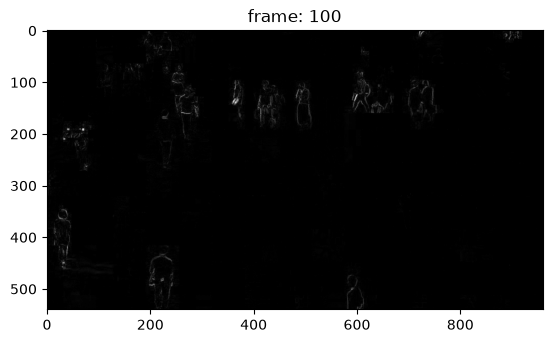

<Figure size 640x480 with 0 Axes>

In [28]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output


vidcap = cv2.VideoCapture(fvideo)
success, image = vidcap.read()
image = image[:, :, ::-1]
count = 1

B = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
Bd = B.astype(float)
Dd = Bd


N = 100

while success and count < N:
    success, image = vidcap.read()
    count += 1
    if success and count <= N:
        clear_output(wait=True)
    image = image[:, :, ::-1]
    F = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    Fd = F.astype(float)
    Dd = np.abs(Bd-Fd)
    Bd = Fd
    plt.figure(1)
    plt.imshow(Dd,cmap='gray')
    plt.title('frame: ' + str(count))
    plt.pause(0.1)
    plt.clf()

**Copyright**

The notebooks are provided as [Open Educational Resource](https://de.wikipedia.org/wiki/Open_Educational_Resources). Feel free to use the notebooks for your own educational purposes. The text is licensed under [Creative Commons Attribution 4.0](https://creativecommons.org/licenses/by/4.0/), the code of the IPython examples under the [MIT license](https://opensource.org/licenses/MIT).